# Visualizations from the preprocessed datasets
### VIZ-A-THON 2026 · using `data_processed/`

This notebook loads the **fresh datasets** exported by `Air_Quality_Analysis.ipynb` and shows
how to build common visualizations from them. Use it as a template — swap stations, dates,
or variables freely.

**Datasets used**
- `hourly_2025_clean.csv.gz` — station × hour (IST + UTC), cleaned pollutants, wind, QC flags
- `daily_model_ready.csv` — station × day, AQI, lags, transport features, targets
- `clean_air_windows_2025.csv` — recommended 3 h daylight window per station-day
- `stations_resolved.csv` — 48 stations with coordinates + coverage

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi":110, "savefig.dpi":160, "font.size":10})
PROC = Path("data_processed"); FIG = Path("figures"); FIG.mkdir(exist_ok=True)
STATE_COLORS = {"Delhi":"#c0392b","Haryana":"#e67e22","Punjab":"#2471a3","Chandigarh":"#1e8449"}

hourly = pd.read_csv(PROC/"hourly_2025_clean.csv.gz")
daily  = pd.read_csv(PROC/"daily_model_ready.csv", parse_dates=["date_ist"])
windows= pd.read_csv(PROC/"clean_air_windows_2025.csv", parse_dates=["date_ist"])
stations=pd.read_csv(PROC/"stations_resolved.csv")
print("hourly", hourly.shape, "| daily", daily.shape, "| windows", windows.shape, "| stations", stations.shape)

hourly (420480, 32) | daily (17520, 185) | windows (9367, 13) | stations (48, 14)


## 1. Time series — daily PM2.5 for selected stations

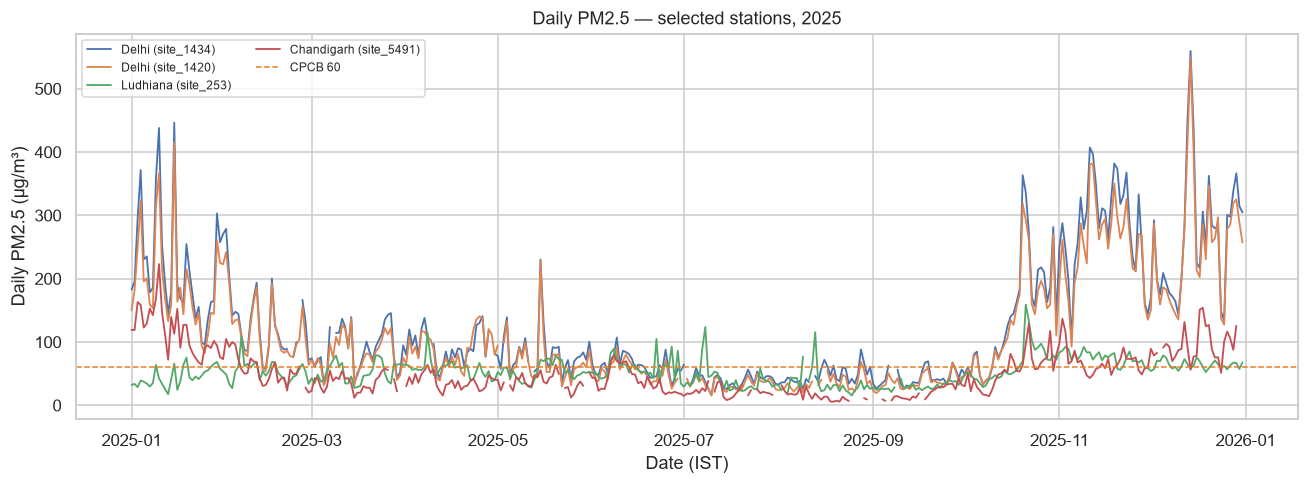

In [2]:
pick = ["site_1434","site_1420","site_253","site_5491"]
fig, ax = plt.subplots(figsize=(12,4.5))
for sid in pick:
    sub = daily[(daily.station_id==sid)].sort_values("date_ist")
    ax.plot(sub.date_ist, sub.pm25_mean, lw=1.2, label=sub.city.iloc[0]+" ("+sid+")")
ax.axhline(60, color="#e67e22", ls="--", lw=1, label="CPCB 60")
ax.set_ylabel("Daily PM2.5 (µg/m³)"); ax.set_xlabel("Date (IST)")
ax.set_title("Daily PM2.5 — selected stations, 2025")
ax.legend(ncol=2, frameon=True, fontsize=8)
fig.tight_layout(); fig.savefig(FIG/"viz01_timeseries.png", bbox_inches="tight"); plt.show()

## 2. Heatmap — hour × month PM2.5 (diurnal fingerprint)

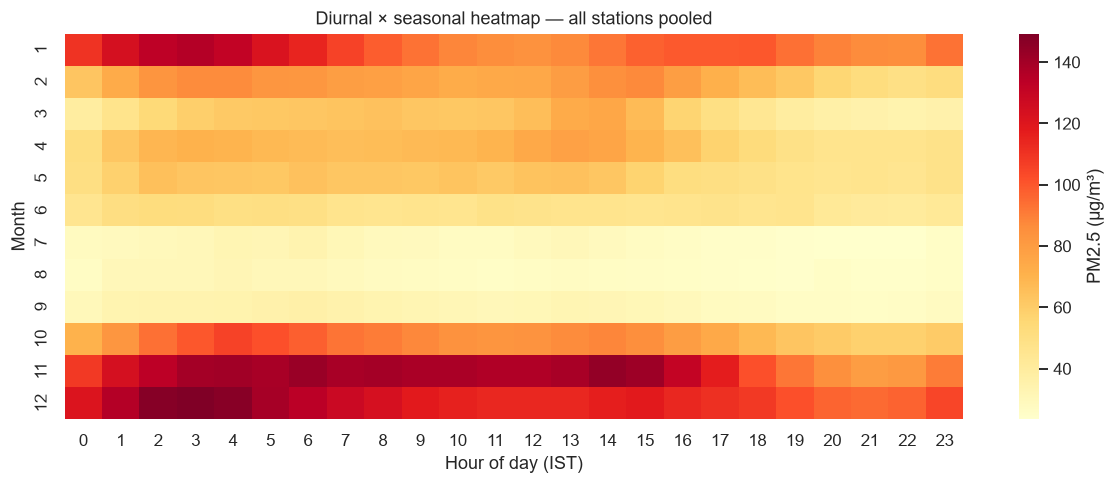

In [3]:
h = hourly.copy()
h["hour"] = pd.to_datetime(h.timestamp_ist).dt.hour
h["month"] = pd.to_datetime(h.timestamp_ist).dt.month
mat = h.groupby(["month","hour"]).pm25.mean().unstack()
fig, ax = plt.subplots(figsize=(11,4.5))
sns.heatmap(mat, cmap="YlOrRd", ax=ax, cbar_kws={"label":"PM2.5 (µg/m³)"})
ax.set_xlabel("Hour of day (IST)"); ax.set_ylabel("Month")
ax.set_title("Diurnal × seasonal heatmap — all stations pooled")
fig.tight_layout(); fig.savefig(FIG/"viz02_heatmap.png", bbox_inches="tight"); plt.show()

## 3. Spatial view — station mean PM2.5 on a map (scatter, size = mean)

C:\Users\manis\AppData\Local\Temp\ipykernel_38556\1337896523.py:13: UserWarning: Glyph 8733 (\N{PROPORTIONAL TO}) missing from font(s) Arial.
  fig.tight_layout(); fig.savefig(FIG/"viz03_map.png", bbox_inches="tight"); plt.show()


C:\Users\manis\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8733 (\N{PROPORTIONAL TO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


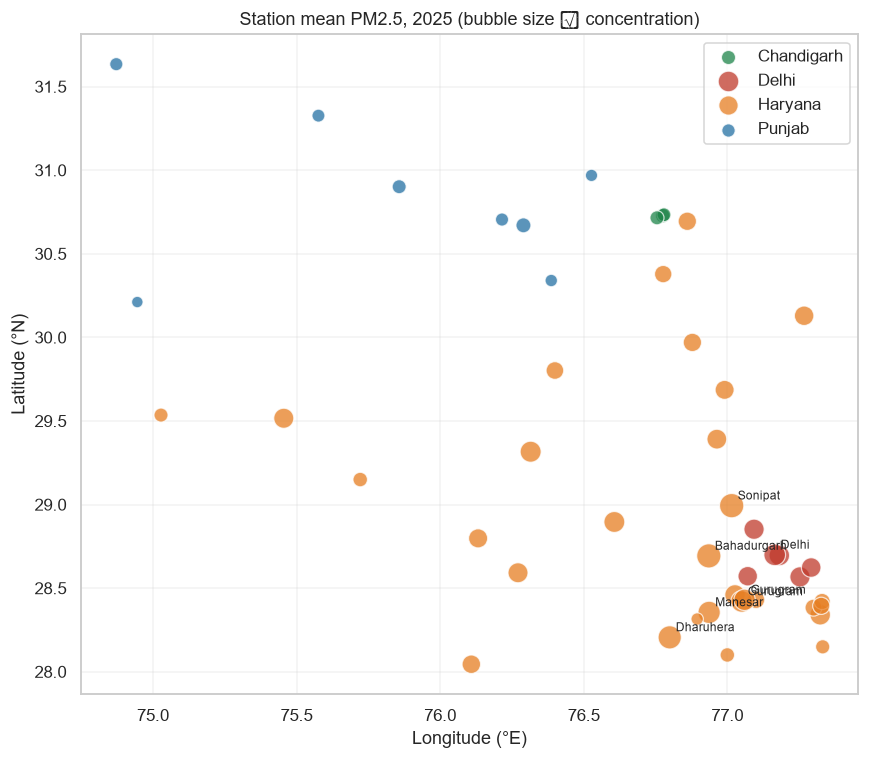

In [4]:
agg = daily.groupby("station_id").agg(pm25=("pm25_mean","mean"), n=("pm25_mean","count")).reset_index()
agg = agg.merge(stations[["station_id","state","lat","lon","city"]], on="station_id", how="left")
fig, ax = plt.subplots(figsize=(8,7))
for s,g in agg.groupby("state"):
    ax.scatter(g.lon, g.lat, s=np.clip(g.pm25,5,400)*1.6, color=STATE_COLORS[s],
               alpha=.75, edgecolor="white", linewidth=.8, label=s)
for _,r in agg.iterrows():
    if r.pm25 >= agg.pm25.quantile(.85):
        ax.annotate(r.city, (r.lon,r.lat), xytext=(4,4), textcoords="offset points", fontsize=8)
ax.set_xlabel("Longitude (°E)"); ax.set_ylabel("Latitude (°N)")
ax.set_title("Station mean PM2.5, 2025 (bubble size ∝ concentration)")
ax.legend(frameon=True); ax.grid(alpha=.25)
fig.tight_layout(); fig.savefig(FIG/"viz03_map.png", bbox_inches="tight"); plt.show()

## 4. Distribution — PM2.5 by state (violin)

C:\Users\manis\AppData\Local\Temp\ipykernel_38556\4267843516.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=daily.dropna(subset=["pm25_mean"]), x="state", y="pm25_mean",


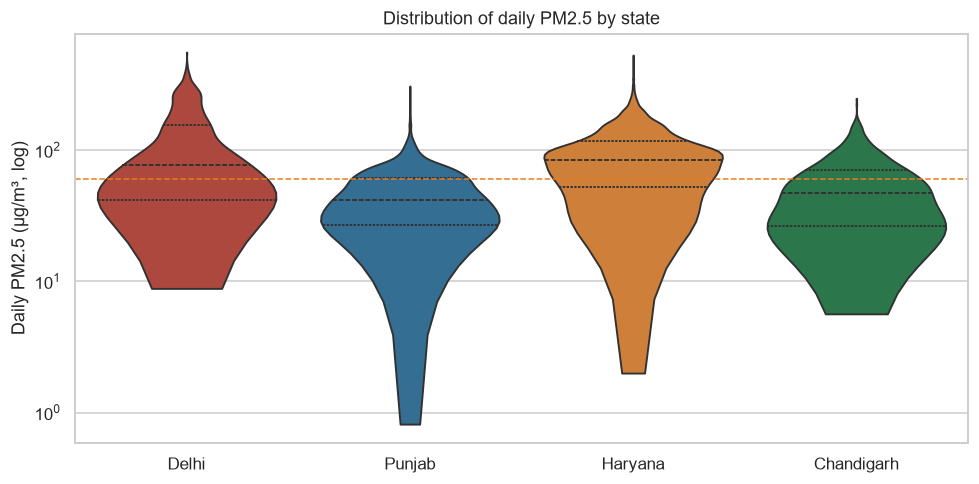

In [5]:
fig, ax = plt.subplots(figsize=(9,4.5))
sns.violinplot(data=daily.dropna(subset=["pm25_mean"]), x="state", y="pm25_mean",
               palette=STATE_COLORS, inner="quartile", cut=0, ax=ax)
ax.set_yscale("log"); ax.axhline(60, color="#e67e22", ls="--", lw=1)
ax.set_ylabel("Daily PM2.5 (µg/m³, log)"); ax.set_xlabel("")
ax.set_title("Distribution of daily PM2.5 by state")
fig.tight_layout(); fig.savefig(FIG/"viz04_violin.png", bbox_inches="tight"); plt.show()

## 5. Wind rose — winter, Delhi (polar)

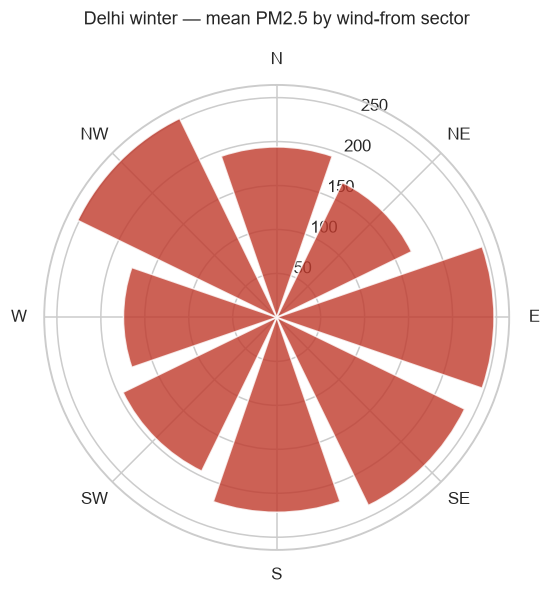

In [6]:
import numpy as np
w = daily[(daily.state=="Delhi") & (daily.month.isin([11,12,1,2]))].dropna(subset=["pm25_mean","wind_dir_deg"])
secs = ["N","NE","E","SE","S","SW","W","NW"]
w["sector"] = pd.cut(w.wind_dir_deg, [0,45,90,135,180,225,270,315,360], labels=secs, include_lowest=True)
rose = w.groupby("sector", observed=True).pm25_mean.mean().reindex(secs)
fig = plt.figure(figsize=(5.5,5.5))
ax = fig.add_subplot(111, projection="polar")
theta = np.deg2rad(np.arange(8)*45)
ax.bar(theta, rose.values, width=np.deg2rad(38), color="#c0392b", alpha=.8, edgecolor="white")
ax.set_theta_zero_location("N"); ax.set_theta_direction(-1)
ax.set_xticks(theta); ax.set_xticklabels(secs)
ax.set_title("Delhi winter — mean PM2.5 by wind-from sector", pad=18)
fig.tight_layout(); fig.savefig(FIG/"viz05_windrose.png", bbox_inches="tight"); plt.show()

## 6. Clean-Air Window — dose reduction distribution

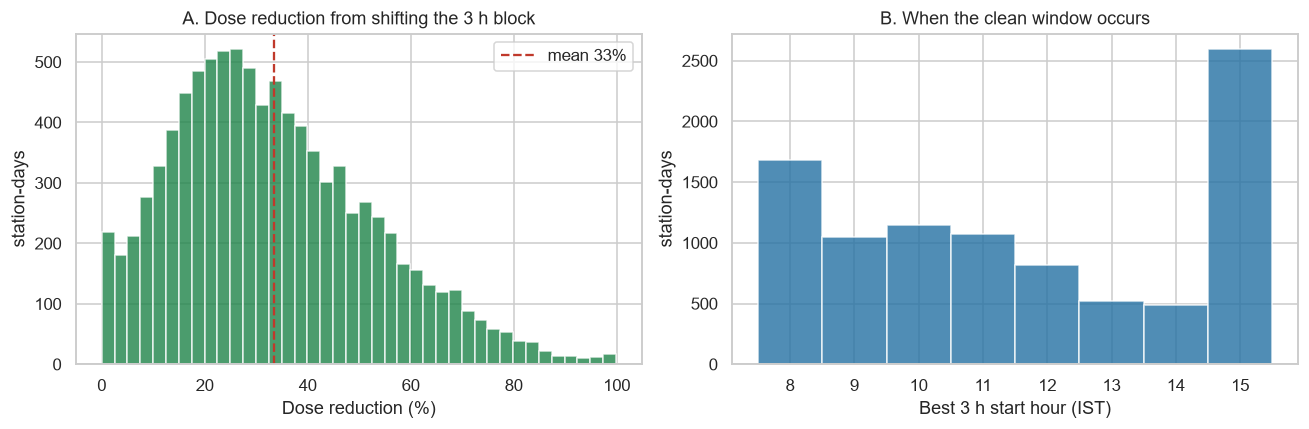

In [7]:
fig, axes = plt.subplots(1,2, figsize=(12,4))
axes[0].hist(windows.dose_reduction_pct.dropna(), bins=40, color="#1e8449", alpha=.8, edgecolor="white")
axes[0].axvline(windows.dose_reduction_pct.mean(), color="#c0392b", ls="--", label=f"mean {windows.dose_reduction_pct.mean():.0f}%")
axes[0].set_xlabel("Dose reduction (%)"); axes[0].set_ylabel("station-days")
axes[0].set_title("A. Dose reduction from shifting the 3 h block"); axes[0].legend(frameon=True)
axes[1].hist(windows.best_start_hour, bins=range(8,17), color="#2471a3", alpha=.8, edgecolor="white", align="left")
axes[1].set_xlabel("Best 3 h start hour (IST)"); axes[1].set_ylabel("station-days")
axes[1].set_title("B. When the clean window occurs")
fig.tight_layout(); fig.savefig(FIG/"viz06_windows.png", bbox_inches="tight"); plt.show()

## 7. Correlation heatmap — daily pollutants & weather

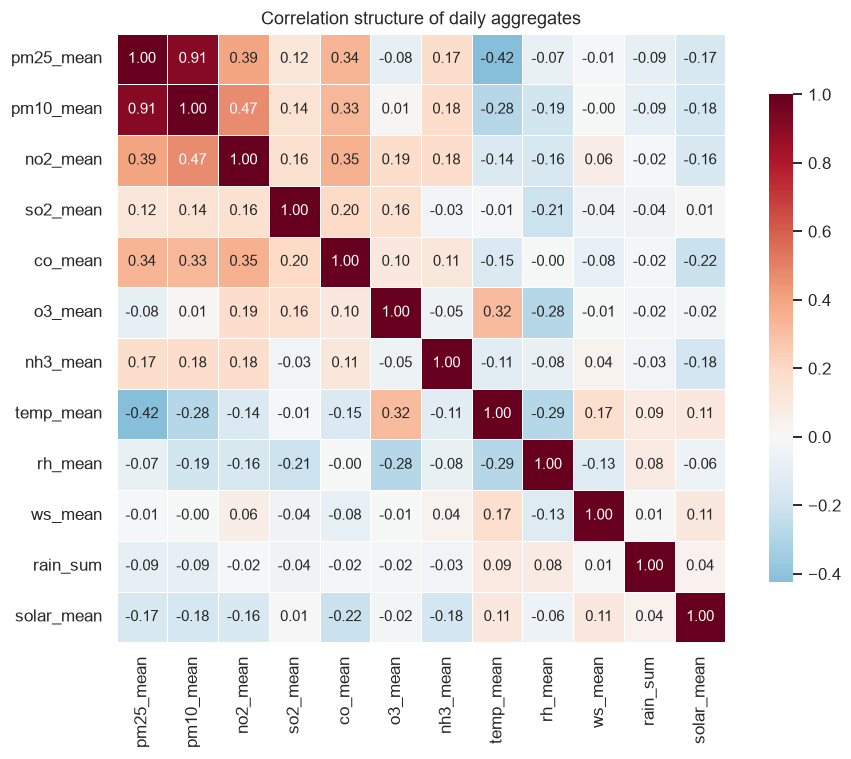

In [8]:
cols = ["pm25_mean","pm10_mean","no2_mean","so2_mean","co_mean","o3_mean","nh3_mean",
        "temp_mean","rh_mean","ws_mean","rain_sum","solar_mean"]
corr = daily[cols].corr()
fig, ax = plt.subplots(figsize=(9,7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, square=True,
            linewidths=.4, cbar_kws={"shrink":.8}, ax=ax)
ax.set_title("Correlation structure of daily aggregates")
fig.tight_layout(); fig.savefig(FIG/"viz07_corr.png", bbox_inches="tight"); plt.show()

## 8. Time series decomposition — monthly mean by state

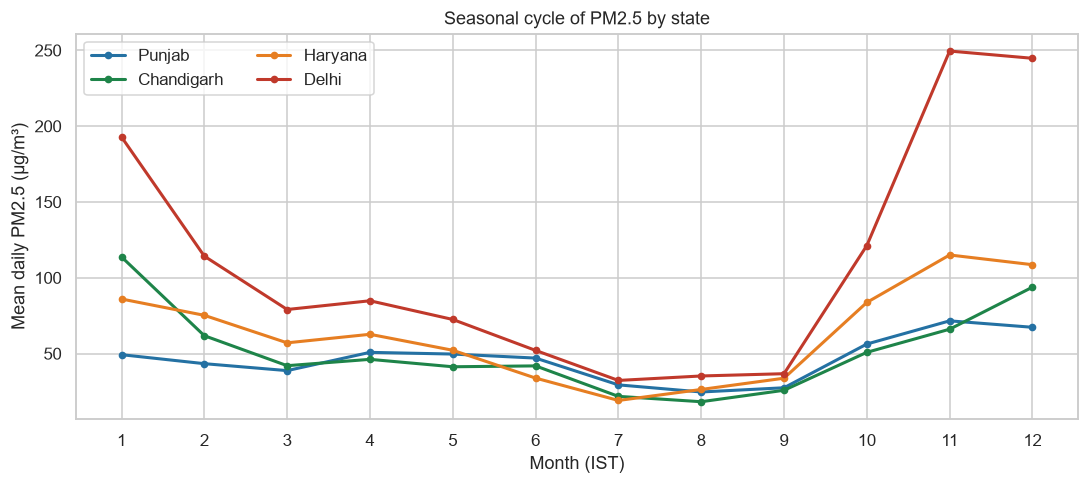

In [9]:
m = daily.dropna(subset=["pm25_mean"]).pivot_table(index="month", columns="state", values="pm25_mean", aggfunc="mean")
fig, ax = plt.subplots(figsize=(10,4.5))
for s in ["Punjab","Chandigarh","Haryana","Delhi"]:
    ax.plot(m.index, m[s], marker="o", ms=4, lw=2, color=STATE_COLORS[s], label=s)
ax.set_xticks(range(1,13)); ax.set_xlabel("Month (IST)"); ax.set_ylabel("Mean daily PM2.5 (µg/m³)")
ax.set_title("Seasonal cycle of PM2.5 by state")
ax.legend(ncol=2, frameon=True)
fig.tight_layout(); fig.savefig(FIG/"viz08_seasonal.png", bbox_inches="tight"); plt.show()

## 9. Tips for your own visualizations

In [10]:
print("Column groups in daily_model_ready.csv:")
print("  identity   :", [c for c in daily.columns if c in ("station_id","state","city","lat","lon")])
print("  pollutants :", [c for c in daily.columns if c.endswith("_mean")][:8])
print("  AQI        :", [c for c in daily.columns if "aqi" in c])
print("  transport  :", [c for c in daily.columns if "upwind" in c or "regional" in c or "regime" in c])
print("  history    :", [c for c in daily.columns if c.startswith("hist_") or c.startswith("prior_")])
print("  targets    :", [c for c in daily.columns if c in ("pm25_next","aqi_next","tier_next","target_ratio")])
print()
print("Useful filters:")
print("  daily[daily.state=='Delhi']")
print("  daily[daily.date_ist.dt.month.isin([11,12,1,2])]")
print("  daily[daily.regime=='Regional transport']")
print("  hourly[hourly.pm25_flag=='ok']")

Column groups in daily_model_ready.csv:
  identity   : ['station_id', 'state', 'city', 'lat', 'lon']
  pollutants : ['pm25_mean', 'pm10_mean', 'no2_mean', 'so2_mean', 'nh3_mean', 'co_mean', 'o3_mean', 'benzene_mean']
  AQI        : ['aqi_n', 'aqi', 'aqi_official', 'aqi_category', 'aqi_lag1', 'aqi_lag2', 'aqi_lag3', 'aqi_lag5', 'aqi_lag7', 'aqi_lag14', 'aqi_lag21', 'aqi_lag28', 'aqi_roll3', 'aqi_roll7', 'aqi_roll14', 'aqi_roll28', 'aqi_next', 'prior_aqi_final', 'prior_aqi_next', 'prior_aqi_ratio_today', 'hist_mean_aqi', 'hist_p90_aqi', 'hist_max_aqi', 'hist_winter_aqi', 'hist_postmon_aqi', 'hist_monsoon_aqi', 'hist_summer_aqi']
  transport  : ['upwind_pm25_d0', 'upwind_pm25_d1', 'upwind_pm25_d2', 'regional_pm25_d0', 'regional_pm25_d1', 'regional_pm25_d2', 'upwind_minus_local', 'regime']
  history    : ['prior_aqi_final', 'prior_pm25', 'prior_pm25_next', 'prior_aqi_next', 'prior_ratio_today', 'prior_aqi_ratio_today', 'hist_mean_aqi', 'hist_p90_aqi', 'hist_max_aqi', 'hist_days', 'hist_win